# Building Realistic DRT Demand from FlipFlop (Hypothesis H-A)

**The question this study needs to answer is not "can the fleet handle everyone in the city," it's "can the fleet handle the people who would actually switch to DRT."**

The first pilot round used every FlipFlop trip regardless of predicted mode ("all modes"), capped at 100 requests, in a 2-hour morning window. That measured an upper-bound stress test, not realistic demand, and the window was copied from an early prototype rather than derived from data. This notebook rebuilds the demand definition from scratch and checks each assumption against data before using it:

1. Use FlipFlop's own **mode-switcher** definition instead of "all modes": a trip counts as DRT demand only if it is `PT` under a DRT-priced scenario but was **not** `PT` in the baseline (drawn from `draws_DRT_Kostenx1.csv` vs `draws_Baseline.csv`, draw 1).
2. Use the **full operating day (06:00-22:00)** instead of a 2-hour morning slice, matching this repo's own H1 convention and checked against MOIA's real hourly pattern below.
3. Restrict to MOIA's coordinate frame (comparable study area) and to the network's **largest connected component** (fixes a routing bug found while preparing this data - see the last section).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

ROOT_DIR = Path.cwd().resolve()
while ROOT_DIR.name != 'FleetPy' and ROOT_DIR.parent != ROOT_DIR:
    ROOT_DIR = ROOT_DIR.parent

# Validated categorical palette (dataviz skill reference palette, light mode) - fixed hue order, never cycled.
BLUE = '#2a78d6'    # MOIA (real observed demand)
ORANGE = '#eb6834'  # FlipFlop DRT switchers (this study's demand definition)
AQUA = '#1baf7a'    # FlipFlop all trips (context / what we are NOT simulating)
INK = '#0b0b0b'
MUTED = '#52514e'

plt.rcParams.update({
    'font.size': 11,
    'axes.edgecolor': '#c9c8c2',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e7e6e1',
    'grid.linewidth': 0.8,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

BASELINE_FILE = ROOT_DIR / 'data' / 'SampleFiles_recovered' / 'SampleFiles' / 'full_draws' / 'draws_Baseline.csv'
DRT_FILE = ROOT_DIR / 'data' / 'SampleFiles_recovered' / 'SampleFiles' / 'full_draws' / 'draws_DRT_Kostenx1.csv'
MOIA_FILE = ROOT_DIR / 'data' / 'demand' / 'trips_klagenfurt.csv'
NETWORK_NODES = ROOT_DIR / 'data' / 'networks' / 'flipflop_neubau_extended' / 'base' / 'nodes.csv'
NETWORK_EDGES = ROOT_DIR / 'data' / 'networks' / 'flipflop_neubau_extended' / 'base' / 'edges.csv'
LARGEST_COMPONENT_FILE = ROOT_DIR / 'data' / 'fleetctrl' / 'initial_vehicle_distribution' / 'flipflop_neubau_extended' / 'largest_component_uniform.csv'
FINAL_DEMAND_FILE = ROOT_DIR / 'data' / 'demand' / 'flipflop_klagenfurt_switchers_pilot' / 'matched' / 'flipflop_neubau_extended' / 'switchers_DRT_Kostenx1_draw1_0600_2200.csv'

DRAW = 1
START_HOUR, END_HOUR = 6, 22

baseline = pd.read_csv(BASELINE_FILE, usecols=['draw', 'trip_id', 'drawn_mode', 'starting_time', 'lat_start', 'lon_start', 'lat_end', 'lon_end'], parse_dates=['starting_time'])
baseline = baseline[baseline['draw'] == DRAW].copy()
drt = pd.read_csv(DRT_FILE, usecols=['draw', 'trip_id', 'drawn_mode'])
drt = drt[drt['draw'] == DRAW]
moia = pd.read_csv(MOIA_FILE)

print(f'FlipFlop draw {DRAW}, full day: {len(baseline):,} trips')
print(f'MOIA real trips: {len(moia):,}')

FlipFlop draw 1, full day: 471,140 trips
MOIA real trips: 1,067


## 1. Why the time window changed

The old pilot used 07:00-09:00 because the first prototype needed *something* small to start with, not because MOIA's demand looks like that. Plotting MOIA's own trips by hour settles it: real demand is spread across the whole day and actually leans toward the evening, not the morning. Restricting FlipFlop's switcher demand to 07:00-09:00 would have kept less than a fifth of the realistic candidate population, for no reason grounded in the real data.

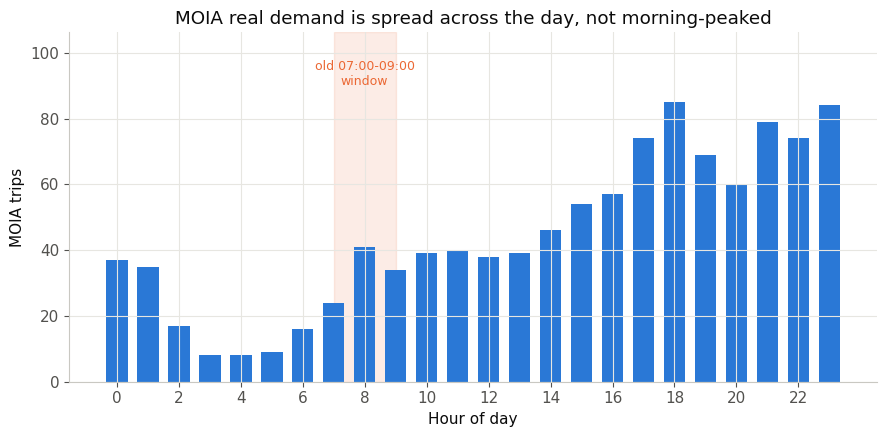

In [2]:
moia_hour = (moia['departure_time'] % 86400) // 3600

fig, ax = plt.subplots(figsize=(9, 4.5))
counts = moia_hour.value_counts().reindex(range(24), fill_value=0).sort_index()
ax.bar(counts.index, counts.values, color=BLUE, width=0.7, label='MOIA real trips (all 1,067)')
ax.axvspan(7, 9, color=ORANGE, alpha=0.12, zorder=0)
ax.text(8, counts.max() * 1.05, 'old 07:00-09:00\nwindow', ha='center', va='bottom', color=ORANGE, fontsize=9)
ax.set_xlabel('Hour of day')
ax.set_ylabel('MOIA trips')
ax.set_title('MOIA real demand is spread across the day, not morning-peaked')
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(0, counts.max() * 1.25)
fig.tight_layout()
plt.show()

## 2. Why "all modes" changed to "mode-switchers"

FlipFlop predicts, per trip, which of Car/PT/Bike/Foot a traveler would choose. "All modes" ignores that prediction entirely - it is the total travel demand of the city, not a DRT forecast. The mode-switcher definition instead asks: **for this trip, does adding a DRT option (priced like PT here) change the predicted mode to something recorded as PT that wasn't PT before?** Only those trips are real DRT candidates.

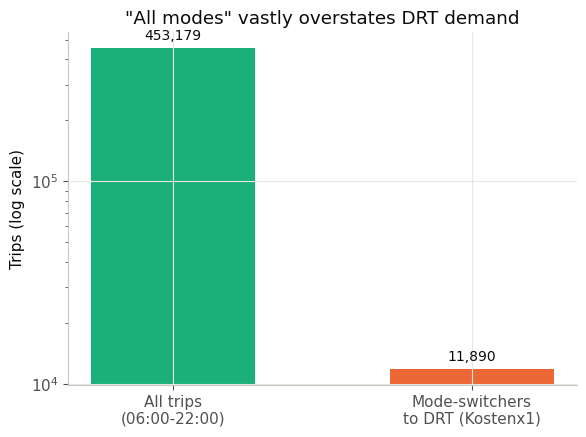

Switchers are 2.6% of all trips in the window.
drawn_mode_base
Car     9944
Bike    1944
Foot       2
Name: switched from, dtype: int64


In [3]:
window = baseline[(baseline['starting_time'].dt.hour >= START_HOUR) & (baseline['starting_time'].dt.hour < END_HOUR)]
merged = window.merge(drt, on='trip_id', suffixes=('_base', '_drt'))
switchers = merged[(merged['drawn_mode_base'] != 'PT') & (merged['drawn_mode_drt'] == 'PT')]

populations = pd.Series({
    'All trips\n(06:00-22:00)': len(window),
    'Mode-switchers\nto DRT (Kostenx1)': len(switchers),
})

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(populations.index, populations.values, color=[AQUA, ORANGE], width=0.55)
ax.set_yscale('log')
ax.set_ylabel('Trips (log scale)')
ax.set_title('"All modes" vastly overstates DRT demand')
for bar, value in zip(bars, populations.values):
    ax.annotate(f'{value:,}', (bar.get_x() + bar.get_width() / 2, value), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=10, color=INK)
fig.tight_layout()
plt.show()

print(f'Switchers are {len(switchers) / len(window):.1%} of all trips in the window.')
print(switchers['drawn_mode_base'].value_counts().rename('switched from'))

### How much does the MOIA-frame restriction itself cut?

Separately from the mode-switcher filter, demand is also restricted to MOIA's coordinate bounding box (kept as a shared comparison area with the real MOIA data, per the earlier study-design review). This is checked on its own so it is not confused with the effect of the mode-switcher filter above.

In [4]:
moia_x = pd.concat([moia['origin_x'], moia['destination_x']])
moia_y = pd.concat([moia['origin_y'], moia['destination_y']])
in_moia_frame = (
    switchers['lon_start'].between(moia_x.min(), moia_x.max())
    & switchers['lat_start'].between(moia_y.min(), moia_y.max())
    & switchers['lon_end'].between(moia_x.min(), moia_x.max())
    & switchers['lat_end'].between(moia_y.min(), moia_y.max())
)
switchers_in_frame = switchers[in_moia_frame]
print(f'Switchers region-wide: {len(switchers):,}')
print(f'Switchers inside the MOIA frame: {len(switchers_in_frame):,} ({len(switchers_in_frame) / len(switchers):.1%})')

Switchers region-wide: 11,890
Switchers inside the MOIA frame: 2,616 (22.0%)


## 3. Does switcher demand still follow a realistic daily rhythm?

Restricting to switchers shrinks the population a lot. The remaining question is whether it still traces a plausible daily shape rather than, say, collapsing to a single hour by artifact of the price scenario. Comparing its hourly shape to MOIA's real hourly shape (both normalized to their own total) is a rough plausibility check, not a formal validation.

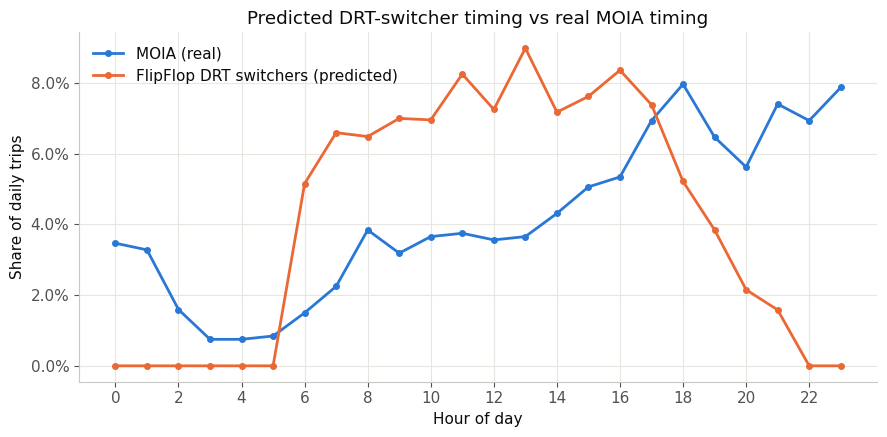

In [5]:
switchers_hour = switchers['starting_time'].dt.hour.value_counts().reindex(range(24), fill_value=0).sort_index()
switchers_share = switchers_hour / switchers_hour.sum()
moia_share = counts / counts.sum()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(moia_share.index, moia_share.values, color=BLUE, marker='o', markersize=4, linewidth=2, label='MOIA (real)')
ax.plot(switchers_share.index, switchers_share.values, color=ORANGE, marker='o', markersize=4, linewidth=2, label='FlipFlop DRT switchers (predicted)')
ax.set_xlabel('Hour of day')
ax.set_ylabel('Share of daily trips')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title('Predicted DRT-switcher timing vs real MOIA timing')
ax.set_xticks(range(0, 24, 2))
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
plt.show()

**Observation:** the two curves broadly track each other during the day (both peak in the evening), but FlipFlop predicts essentially **zero** switcher demand overnight (00:00-05:00, 22:00-23:00) while MOIA shows real, non-trivial demand in exactly those hours. This is a genuine divergence worth carrying into the plausibility check against MOIA (hypothesis H-C), not a bug: it likely reflects PT service not running overnight in the choice model (so a trip can never be predicted as switching to a PT-priced DRT option at 3am), whereas a real DRT/ridepooling service can and does operate overnight. If the simulated fleet is sized only for the shape FlipFlop predicts, it would understaff exactly the hours where real demand doesn't drop to zero.

## 4. A routing bug found while building this demand

Snapping each trip's origin/destination to its nearest network node is not enough on its own - a node can be geometrically close but sit in a small, disconnected piece of the street graph (a service road that dead-ends against something the extraction from `klagenfurt_network_extended.gpkg` didn't connect through). FleetPy cannot route to or from those nodes, so any request assigned to one is unroutable regardless of fleet size - a data bug that would silently masquerade as a capacity problem.

A first version of the switcher-demand pipeline only checked "does this node appear in some edge," not "is this node in the network's largest connected component." Running it produced over 100 `no route found` warnings within the first 20% of simulated time. Filtering to the largest connected component (36,821 of 43,137 nodes, already computed by this study's network builder) removed the affected requests before simulation rather than let them fail silently during it.

In [6]:
nodes = pd.read_csv(NETWORK_NODES)
edges = pd.read_csv(NETWORK_EDGES)
any_edge_nodes = pd.unique(edges[['from_node', 'to_node']].to_numpy().ravel())
largest_component = pd.read_csv(LARGEST_COMPONENT_FILE)
connected_nodes = set(largest_component['node_index'].astype(int))

print(f'Nodes in the network: {len(nodes):,}')
print(f'Nodes appearing in at least one edge (the old, insufficient check): {len(any_edge_nodes):,}')
print(f'Nodes in the largest connected component (the fix): {len(connected_nodes):,}')
print(f'Nodes that pass the old check but are NOT actually reachable: {len(set(any_edge_nodes) - connected_nodes):,}')

Nodes in the network: 43,137
Nodes appearing in at least one edge (the old, insufficient check): 43,137
Nodes in the largest connected component (the fix): 36,821
Nodes that pass the old check but are NOT actually reachable: 6,316


## 5. Final demand definition for hypothesis H-A

The demand file used for the feasibility simulation (`switchers_DRT_Kostenx1_draw1_0600_2200.csv`) is the result of every filter above applied together: draw 1, DRT-at-PT-tariff mode-switchers, 06:00-22:00, inside the MOIA coordinate frame, and snapped only to the network's largest connected component.

In [7]:
final_demand = pd.read_csv(FINAL_DEMAND_FILE)

summary = pd.DataFrame([
    {'stage': 'Old pilot: all modes, 07:00-09:00, capped', 'requests': 100},
    {'stage': 'All trips, 06:00-22:00 (context, not simulated)', 'requests': len(window)},
    {'stage': 'Mode-switchers, 06:00-22:00, MOIA frame (pre network filter)', 'requests': len(switchers_in_frame)},
    {'stage': 'Final H-A demand (also filtered to largest connected component)', 'requests': len(final_demand)},
])
summary['requests'] = summary['requests'].map('{:,}'.format)
summary

,stage,requests
0,"Old pilot: all modes, 07:00-09:00, capped",100
1,"All trips, 06:00-22:00 (context, not simulated)","453,179"
2,"Mode-switchers, 06:00-22:00, MOIA frame (pre n...","2,616"
3,Final H-A demand (also filtered to largest con...,"2,066"
